# Multistage scenario tree with non-anticipativity

**Texas TVEF battery case study, uncertainty-aware design under progressively revealed information.**

The deterministic models (`Texas TVEF Battery gurobipy.ipynb`) optimise design and dispatch with perfect foresight of
all 8760 hours. Here the operational uncertainties are revealed stage by stage on a scenario tree
(`tvef_model.ScenarioTree`) and the model (`tvef_model.H2SystemTree`) may only use information that is available at
each node:

- stage 0 (root): the design, i.e. capacities $Cap^P, Cap^S$ and the network binaries $X^P, X^S$, is fixed before
  anything is known (here-and-now);
- stage $k \ge 1$: a block of days whose realization of the uncertain handles (grid emission-factor profile, gas and
  electricity price levels, ...) becomes known at the start of the block; dispatch inside the block may depend on it
  and on the past, but not on later blocks.

**Non-anticipativity.** In the *node formulation* every tree node owns the operational variables of its time slice
and is linked to its parent through the inventory, ramp and smoothing constraints at the boundary hour. Scenarios that
share history share the node and therefore the same decisions, so non-anticipativity holds by construction. The
*explicit formulation* (`explicit_nac=True`) copies the variables per scenario and adds the equalities
$x_{s,t} = x_{s',t}$ for all hours $t$ before scenarios $s, s'$ separate. Both are built below on a small instance
and give the same objective; the node formulation is about half the size.

**Binaries.** Only Grid, PV and WF have a binding minimum size (`prod_min = prod_max`), and every solution of this
case study builds all three, so the tree models fix the network binaries at 1 (`fix_binaries=True`, capacities stay
continuous). The tree is then a pure LP that Gurobi's barrier solves in a few minutes; as a MIP the crossover /
simplex root basis on this degenerate 3 M-variable LP takes an order of magnitude longer. `fix_binaries=False`
restores the MIP. Barrier without crossover returns an interior optimal point, so capacities that are not needed can
show small positive values (a few hundred kg/hr of PEM, worth well under 0.001 % of the objective); treat values
below ~1 % of the main capacities as zero. Big-M declarations (1e8) are mapped to true infinity for conditioning.

Standard stochastic-programming diagnostics are computed: the recourse problem (RP), the wait-and-see solution (WS,
perfect information per scenario), the expected value of perfect information (EVPI = RP − WS), the expected-value
design evaluated on the tree (EEV) and the value of the stochastic solution (VSS = EEV − RP).

__author__ = "Marco De Sousa"
__copyright__ = "Copyright 2023, Multi-parametric Optimization & Control Lab"
__credits__ = ["Marco De Sousa", "Rahul Kakodkar", "Efstratios N. Pistikopoulos"]
__license__ = "MIT"
__version__ = "1.1.0"
__maintainer__ = "Marco De Sousa"
__email__ = "marcopdsousa@tamu.edu"
__status__ = "Production"

## Formulation

Tree $\mathcal{N}$ with root $0$, node time slices $\mathcal{T}_n$, parent $a(n)$, unconditional probability $\pi_n$,
leaves (scenarios) $\mathcal{L}$ with paths $\mathcal{P}_\ell$.

\begin{align}
\min\; & \sum_p (Capex_p + Fopex_p)\,Cap^P_p + Capex^S Cap^S + \sum_{n \ne 0} \pi_n \Big( \sum_{p, t \in \mathcal{T}_n} Vopex_p P^n_{p,t} + \sum_{r, t \in \mathcal{T}_n} Price^n_{r,t} C^n_{r,t} \Big) \\
\text{s.t. } & C^n_{r,t} + \sum_p \eta^n_{p,r} P^n_{p,t} - S^n_{r,t} = Inv^n_{r,t} - Inv^n_{r,t-1} \quad (Inv^n_{r,t_0(n)-1} \equiv Inv^{a(n)}_{r,t_1(a(n))}) \\
& P^n_{p,t} \le \phi^n_{p,t} Cap^P_p, \quad Inv^n_{r,t} \le Cap^S_r, \quad \textstyle\sum_{t \in d} S^n_{H_2,t} \;(=,\ge)\; D_d \\
& \text{ramp / min-load / smoothing of } P^n \text{ with the parent's last hours as history} \\
& GWP_\ell = \sum_{n \in \mathcal{P}_\ell} \sum_s GWP^n_s \le \epsilon \quad \forall \ell \in \mathcal{L} \;\; \text{(per-scenario cap)} \quad \text{or} \quad \sum_n \pi_n GWP^n \le \epsilon \;\; \text{(expected cap)}
\end{align}

## Setup

In [1]:
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tvef_model as tm
from tvef_model import ScenarioTree, H2SystemTree, H2System, make_inputs, PARAMS

data = tm.load_case_data()
pd.set_option('display.width', 160)

## 1. Verification on a 30-day instance

- a single-scenario tree (chain) must reproduce the deterministic model, also when the chain is cut into several
  stages (this checks the parent-child linking of inventory, ramp and smoothing);
- the node formulation and the explicit non-anticipativity formulation must give the same objective.

In [2]:
nominal = make_inputs(data)
det30 = H2System(nominal, 'cost', 'eq', n_days=30)
det30.solve(tee=False, Crossover=1)
chain1 = H2SystemTree(data, ScenarioTree.chain([30]), 'cost', 'eq')
chain1.solve(tee=False, Crossover=1)
chain3 = H2SystemTree(data, ScenarioTree.chain([10, 10, 10]), 'cost', 'eq')
chain3.solve(tee=False, Crossover=1)
print(f'deterministic 30 days : {det30.m.ObjVal:,.4f} USD')
print(f'chain, 1 stage        : {chain1.m.ObjVal:,.4f} USD   (diff {chain1.m.ObjVal - det30.m.ObjVal:.2e})')
print(f'chain, 3 stages       : {chain3.m.ObjVal:,.4f} USD   (diff {chain3.m.ObjVal - det30.m.ObjVal:.2e})')

Set parameter Username


Academic license - for non-commercial use only - expires 2027-03-30


deterministic 30 days : 16,507,690.8568 USD
chain, 1 stage        : 16,507,690.8568 USD   (diff 2.42e-08)
chain, 3 stages       : 16,507,690.8568 USD   (diff 1.96e-07)


In [3]:
branches_small = {
    'low':  (0.25, {'grid_ef_profile': '0.25', 'elec_price_level': 0.9, 'gas_price_level': 0.8}),
    'mid':  (0.50, {}),
    'high': (0.25, {'grid_ef_profile': '0.75', 'elec_price_level': 1.1, 'gas_price_level': 1.2}),
}
tree_small = ScenarioTree.product([10, 10, 10], branches_small)
print(tree_small)
node_form = H2SystemTree(data, tree_small, 'cost', 'eq')
node_form.solve(tee=False, Crossover=1)
explicit = H2SystemTree(data, tree_small, 'cost', 'eq', explicit_nac=True)
explicit.solve(tee=False, Crossover=1)
print(f'node formulation : {node_form.m.NumVars:>9,} variables, objective {node_form.m.ObjVal:,.4f}  (build {node_form.build_time:.0f} s, solve {node_form.solve_time:.0f} s)')
print(f'explicit NAC     : {explicit.m.NumVars:>9,} variables, {explicit.n_nac:,} non-anticipativity equalities, '
      f'objective {explicit.m.ObjVal:,.4f}  (build {explicit.build_time:.0f} s, solve {explicit.solve_time:.0f} s)')
print(f'difference       : {explicit.m.ObjVal - node_form.m.ObjVal:.2e}')
del explicit

ScenarioTree(40 nodes, 27 scenarios, 30 days)


node formulation :   430,592 variables, objective 16,507,675.8374  (build 13 s, solve 7 s)
explicit NAC     :   894,272 variables, 463,680 non-anticipativity equalities, objective 16,507,675.8374  (build 31 s, solve 38 s)
difference       : 1.29e-06


In [4]:
tree_small.table()

,stage,parent,label,day_start,day_end,cond_prob,prob,overrides
node,,,,,,,,
0,0,NaN,root,0,0,1.00,1.000000,{}
1,1,0.0,low,0,10,0.25,0.250000,"{'grid_ef_profile': '0.25', 'elec_price_level'..."
14,1,0.0,mid,0,10,0.50,0.500000,{}
27,1,0.0,high,0,10,0.25,0.250000,"{'grid_ef_profile': '0.75', 'elec_price_level'..."
2,2,1.0,low,10,20,0.25,0.062500,"{'grid_ef_profile': '0.25', 'elec_price_level'..."
6,2,1.0,mid,10,20,0.50,0.125000,"{'grid_ef_profile': '0.25', 'elec_price_level'..."
10,2,1.0,high,10,20,0.25,0.062500,"{'grid_ef_profile': '0.75', 'elec_price_level'..."
15,2,14.0,low,10,20,0.25,0.125000,"{'grid_ef_profile': '0.25', 'elec_price_level'..."
19,2,14.0,mid,10,20,0.50,0.250000,{}


## 2. Full-year tree

Four quarterly stages, each revealing a *low-carbon* or *high-carbon* quarter with equal probability. A branch is a
joint realization of the wait-and-see handles (the correlation between the grid emission factor and the fuel/power
price levels is a modelling choice; make the branches independent per handle if you prefer, at the cost of more
scenarios). The nominal case (mean profile, level 1.0) is the expectation of the two branches.

1 + 2 + 4 + 8 + 16 = 31 nodes, 16 scenarios, each node covering 91 or 92 days.

In [5]:
branches = {
    'low-carbon':  (0.5, {'grid_ef_profile': '0.25', 'gas_price_level': 0.8, 'elec_price_level': 0.9}),
    'high-carbon': (0.5, {'grid_ef_profile': '0.75', 'gas_price_level': 1.2, 'elec_price_level': 1.1}),
}
STAGE_DAYS = [91, 91, 91, 92]
tree = ScenarioTree.product(STAGE_DAYS, branches)
print(tree)
tree.table().head(8)

ScenarioTree(31 nodes, 16 scenarios, 365 days)


,stage,parent,label,day_start,day_end,cond_prob,prob,overrides
node,,,,,,,,
0,0,NaN,root,0,0,1.0,1.000,{}
1,1,0.0,low-carbon,0,91,0.5,0.500,"{'grid_ef_profile': '0.25', 'gas_price_level':..."
16,1,0.0,high-carbon,0,91,0.5,0.500,"{'grid_ef_profile': '0.75', 'gas_price_level':..."
2,2,1.0,low-carbon,91,182,0.5,0.250,"{'grid_ef_profile': '0.25', 'gas_price_level':..."
9,2,1.0,high-carbon,91,182,0.5,0.250,"{'grid_ef_profile': '0.75', 'gas_price_level':..."
17,2,16.0,low-carbon,91,182,0.5,0.250,"{'grid_ef_profile': '0.25', 'gas_price_level':..."
24,2,16.0,high-carbon,91,182,0.5,0.250,"{'grid_ef_profile': '0.75', 'gas_price_level':..."
3,3,2.0,low-carbon,182,273,0.5,0.125,"{'grid_ef_profile': '0.25', 'gas_price_level':..."


### 2a. Recourse problem without an emission cap (cost minimization)

In [6]:
rp0 = H2SystemTree(data, tree, 'cost', 'eq')
print(f'{rp0.m.NumVars:,} variables, {rp0.m.NumConstrs:,} constraints, built in {rp0.build_time:.0f} s')
rp0.solve(tee=True)
rp0.summary()
res_rp0 = rp0.results()
res_rp0['scenarios'].round(0)

3,031,616 variables, 4,154,625 constraints, built in 169 s
Set parameter OutputFlag to value 1


Set parameter Method to value 2


Set parameter Crossover to value 0


Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11+.0 (26200.2))


CPU model: 13th Gen Intel(R) Core(TM) i7-13700, instruction set [SSE2|AVX|AVX2]


Thread count: 16 physical cores, 24 logical processors, using up to 24 threads


... (127 outputs left out)

Optimal objective 2.57643731e+08


termination: optimal  (build 169.0 s, solve 186.5 s)


termination : optimal  (ScenarioTree(31 nodes, 16 scenarios, 365 days); node formulation)
objective   : 257,643,731.32  (cost)
exp. cost   : 257,643,731.32 USD  (capex 183,502, fopex 1,702, exp. opex 257,458,527)
exp. GWP    : 1,447,046,246.80 kg CO2e  (scope 1 1,038,755,657, scope 2 31,725,384, scope 3 376,565,206)
capacities  : ATR_CCS_R 0.0, ATR_CCS_R_OC 0.0, AWE 0.2, D1 0.0, Grid 56.9, LiI 25.0, LiI_discharge 25.0, PEM 411.9, PV 600.0, SMR 23,567.7, SMRCCS 0.3, WF 650.0
storage     : LiI_Power_stored 142.54


,path,prob,cost,gwp_scope1,gwp_scope2,gwp_scope3,gwp_total
scenario,,,,,,,
4,low-carbon > low-carbon > low-carbon > low-carbon,0.0,215466927.0,1.038795e+09,25979994.0,376579388.0,1.441354e+09
5,low-carbon > low-carbon > low-carbon > high-ca...,0.0,239625261.0,1.038762e+09,29089512.0,376567667.0,1.444420e+09
7,low-carbon > low-carbon > high-carbon > low-ca...,0.0,242037535.0,1.038795e+09,28419551.0,376579388.0,1.443794e+09
8,low-carbon > low-carbon > high-carbon > high-c...,0.0,266196036.0,1.038762e+09,31531486.0,376567666.0,1.446862e+09
11,low-carbon > high-carbon > low-carbon > low-ca...,0.0,232778742.0,1.038795e+09,28545105.0,376579388.0,1.443919e+09
12,low-carbon > high-carbon > low-carbon > high-c...,0.0,256937077.0,1.038762e+09,31654623.0,376567667.0,1.446985e+09
14,low-carbon > high-carbon > high-carbon > low-c...,0.0,259349525.0,1.038795e+09,30987678.0,376579388.0,1.446362e+09
15,low-carbon > high-carbon > high-carbon > high-...,0.0,283508027.0,1.038762e+09,34099612.0,376567666.0,1.449430e+09
19,high-carbon > low-carbon > low-carbon > low-ca...,0.0,231779572.0,1.038749e+09,29352517.0,376562745.0,1.444664e+09


### 2b. Recourse problem with a 50 % emission-reduction target

The cap is the one used in the deterministic epsilon-constraint sweep (50 % below the cost-optimal GWP of
1,447,319,785 kg CO2e). Two ways to impose it on a tree:
- **per scenario** (`mode='each'`): every realization must meet the target, a robust reading of the policy;
- **in expectation** (`mode='expected'`): the target holds on average over the tree.

In [7]:
GWP_BASE = 1447319785.076017        # cost-optimal GWP of the deterministic model (same base as the epsilon sweep)
TARGET_PCT = 50

rp_each = H2SystemTree(data, tree, 'cost', 'geq')
rp_each.add_gwp_reduction(GWP_BASE, TARGET_PCT, mode='each')
rp_each.solve(tee=False)
rp_each.summary()
res_each = rp_each.results()

termination : optimal  (ScenarioTree(31 nodes, 16 scenarios, 365 days); node formulation)
objective   : 274,834,731.01  (cost)
exp. cost   : 274,834,731.01 USD  (capex 258,894, fopex 2,101, exp. opex 274,573,736)
exp. GWP    : 723,659,892.54 kg CO2e  (scope 1 270,590,749, scope 2 103,560,598, scope 3 349,508,546)
capacities  : ATR_CCS_R 22,702.7, ATR_CCS_R_OC 0.0, AWE 0.0, D1 0.0, D2 0.0, D3 0.0, D4 0.0, Grid 86.1, LiI 25.0, LiI_discharge 25.0, PEM 0.0, PV 600.0, SMR 4,740.8, SMRCCS 0.0, WF 650.0
storage     : LiI_Power_stored 200.00


In [8]:
rp_exp = H2SystemTree(data, tree, 'cost', 'geq')
rp_exp.add_gwp_reduction(GWP_BASE, TARGET_PCT, mode='expected')
rp_exp.solve(tee=False)
rp_exp.summary()
res_exp = rp_exp.results()

termination : optimal  (ScenarioTree(31 nodes, 16 scenarios, 365 days); node formulation)
objective   : 274,821,584.13  (cost)
exp. cost   : 274,821,584.13 USD  (capex 258,894, fopex 2,101, exp. opex 274,560,589)
exp. GWP    : 723,659,892.54 kg CO2e  (scope 1 270,352,493, scope 2 103,807,250, scope 3 349,500,150)
capacities  : ATR_CCS_R 22,692.8, ATR_CCS_R_OC 0.0, AWE 0.0, D1 0.0, D2 0.0, D3 0.0, D4 0.0, Grid 86.1, LiI 25.0, LiI_discharge 25.0, PEM 0.0, PV 600.0, SMR 4,759.3, SMRCCS 0.0, WF 650.0
storage     : LiI_Power_stored 200.00


In [9]:
design_cmp = pd.DataFrame({'no cap': res_rp0['design']['Cap_P'], '50 % cap per scenario': res_each['design']['Cap_P'],
                           '50 % cap expected': res_exp['design']['Cap_P']})
design_cmp.loc['LiI_Power_stored [MWh]'] = [res_rp0['design']['Cap_S'].iloc[0], res_each['design']['Cap_S'].iloc[0], res_exp['design']['Cap_S'].iloc[0]]
design_cmp = design_cmp[(design_cmp > 0).any(axis=1)]
design_cmp.round(1)

,no cap,50 % cap per scenario,50 % cap expected
ATR_CCS_R,0.0,22702.7,22692.8
ATR_CCS_R_OC,0.0,0.0,0.0
AWE,0.2,0.0,0.0
D1,0.0,0.0,0.0
D2,0.0,0.0,0.0
D3,0.0,0.0,0.0
D4,0.0,0.0,0.0
Grid,56.9,86.1,86.1
LiI,25.0,25.0,25.0
LiI_discharge,25.0,25.0,25.0


In [10]:
pd.concat({'per scenario': res_each['scenarios'][['path', 'prob', 'cost', 'gwp_total']],
           'expected': res_exp['scenarios'][['cost', 'gwp_total']]}, axis=1).round(0)

per scenario                                    expected             
                                                       path prob         cost    gwp_total         cost    gwp_total
scenario                                                                                                            
4         low-carbon > low-carbon > low-carbon > low-carbon  0.0  234931829.0  723659893.0  234283825.0  746999908.0
5         low-carbon > low-carbon > low-carbon > high-ca...  0.0  257675140.0  723659893.0  257295144.0  737385892.0
7         low-carbon > low-carbon > high-carbon > low-ca...  0.0  259818047.0  723659893.0  259246170.0  744220121.0
8         low-carbon > low-carbon > high-carbon > high-c...  0.0  282561064.0  723659893.0  282256576.0  734656450.0
11        low-carbon > high-carbon > low-carbon > low-ca...  0.0  251461481.0  723659893.0  251599270.0  718101990.0
12        low-carbon > high-carbon > low-carbon > high-c...  0.0  274210836.0  723659893.0  274610589.0  708487974.0
14        low-carbon > high-carbon > high-carbon > low-c...  0.0  276343478.0  723659893.0  276561494.0  715341980.0
15        low-carbon > high-carbon > high-carbon > high-...  0.0  299116249.0  723659893.0  299571900.0  705778308.0
19        high-carbon > low-carbon > low-carbon > low-ca...  0.0  250567264.0  723659893.0  250070615.0  741571501.0
20        high-carbon > low-carbon > low-carbon > high-c...  0.0  273310884.0  723659893.0  273081934.0  731957485.0
22        high-carbon > low-carbon > high-carbon > low-c...  0.0  275453157.0  723659893.0  275032959.0  738791714.0
23        high-carbon > low-carbon > high-carbon > high-...  0.0  298196375.0  723659893.0  298043365.0  729228043.0
26        high-carbon > high-carbon > low-carbon > low-c...  0.0  267103886.0  723659893.0  267386333.0  712683656.0
27        high-carbon > high-carbon > low-carbon > high-...  0.0  289855042.0  723659893.0  290397652.0  703069639.0
29        high-carbon > high-carbon > high-carbon > low-...  0.0  291985777.0  723659893.0  292348557.0  709923646.0
30        high-carbon > high-carbon > high-carbon > high...  0.0  314765189.0  723659893.0  315358963.0  700359974.0

## 3. Value of information: EVPI and VSS (50 % target, per-scenario cap)

- **WS**: each scenario solved with perfect information (a chain tree along its path), weighted by probability.
- **EV / EEV**: the design of the nominal (expected-value) scenario, fixed and evaluated on the tree.

In [11]:
t0 = time.time()
ws_rows = []
for leaf in tree.leaves:
    path = tree.scenario_path(leaf)
    chain = ScenarioTree.chain(STAGE_DAYS, [n.overrides for n in path])
    mdl = H2SystemTree(data, chain, 'cost', 'geq')
    mdl.add_gwp_reduction(GWP_BASE, TARGET_PCT, mode='each')
    mdl.solve(tee=False)
    ws_rows.append(dict(scenario=leaf.id, path=' > '.join(n.label for n in path), prob=leaf.prob, status=mdl.status,
                        cost=mdl.m.ObjVal if mdl.status == 'optimal' else np.nan,
                        SMR=mdl.design()['Cap_P']['SMR'] if mdl.status == 'optimal' else np.nan,
                        ATR_CCS_R=mdl.design()['Cap_P']['ATR_CCS_R'] if mdl.status == 'optimal' else np.nan,
                        battery=mdl.design()['Cap_S'].iloc[0] if mdl.status == 'optimal' else np.nan))
    del mdl
ws_df = pd.DataFrame(ws_rows).set_index('scenario')
WS = float((ws_df['prob'] * ws_df['cost']).sum())
print(f'{len(ws_rows)} perfect-information solves in {time.time() - t0:.0f} s')
ws_df.round(1)

16 perfect-information solves in 618 s


,path,prob,status,cost,SMR,ATR_CCS_R,battery
scenario,,,,,,,
4,low-carbon > low-carbon > low-carbon > low-carbon,0.1,optimal,234911020.4,5366.3,22097.7,200.0
5,low-carbon > low-carbon > low-carbon > high-ca...,0.1,optimal,257670709.2,4923.3,22654.6,200.0
7,low-carbon > low-carbon > high-carbon > low-ca...,0.1,optimal,259815199.0,4750.5,22359.6,200.0
8,low-carbon > low-carbon > high-carbon > high-c...,0.1,optimal,282555730.7,4557.8,22907.8,200.0
11,low-carbon > high-carbon > low-carbon > low-ca...,0.1,optimal,251424677.3,5626.9,21956.8,200.0
12,low-carbon > high-carbon > low-carbon > high-c...,0.1,optimal,274199859.0,5140.3,22447.8,200.0
14,low-carbon > high-carbon > high-carbon > low-c...,0.1,optimal,276336466.4,4951.2,22361.3,200.0
15,low-carbon > high-carbon > high-carbon > high-...,0.1,optimal,299102729.4,4865.8,22675.2,200.0
19,high-carbon > low-carbon > low-carbon > low-ca...,0.1,optimal,250559322.2,5000.4,22514.6,200.0


In [12]:
ev = H2SystemTree(data, ScenarioTree.chain(STAGE_DAYS), 'cost', 'geq')      # expected-value (nominal) scenario
ev.add_gwp_reduction(GWP_BASE, TARGET_PCT, mode='each')
ev.solve(tee=False)
EV = ev.m.ObjVal
eev = H2SystemTree(data, tree, 'cost', 'geq')
eev.add_gwp_reduction(GWP_BASE, TARGET_PCT, mode='each')
eev.fix_design(ev.design())
eev.solve(tee=False)
EEV = eev.m.ObjVal if eev.status == 'optimal' else np.nan
RP = rp_each.m.ObjVal

value_table = pd.Series({'WS (perfect information)': WS, 'RP (recourse problem)': RP, 'EV (nominal scenario)': EV,
                         'EEV (nominal design on the tree)': EEV, 'EVPI = RP - WS': RP - WS, 'VSS = EEV - RP': EEV - RP},
                        name='USD')
print(f'EEV status: {eev.status}  (an infeasible EEV means the nominal design cannot meet the target in every scenario)')
value_table.round(0)

EEV status: optimal  (an infeasible EEV means the nominal design cannot meet the target in every scenario)


WS (perfect information)            274822635.0
RP (recourse problem)               274834731.0
EV (nominal scenario)               274908730.0
EEV (nominal design on the tree)    274836810.0
EVPI = RP - WS                          12096.0
VSS = EEV - RP                           2079.0
Name: USD, dtype: float64

In [13]:
with open('Gurobipy_tree_results.pkl', 'wb') as f:
    pickle.dump({'rp0': res_rp0, 'rp_each': res_each, 'rp_expected': res_exp, 'ws': ws_df, 'value_of_information': value_table,
                 'tree': tree.table(), 'branches': branches, 'stage_days': STAGE_DAYS}, f)

## 4. What non-anticipativity looks like

Production of the reforming routes along all 16 scenarios around the first stage boundary (day 91). Before the
boundary every scenario follows the same trajectory (the stage-1 node is shared); after it, the trajectories
separate according to the realized quarter, but only two distinct paths exist in stage 2, four in stage 3, and so on.

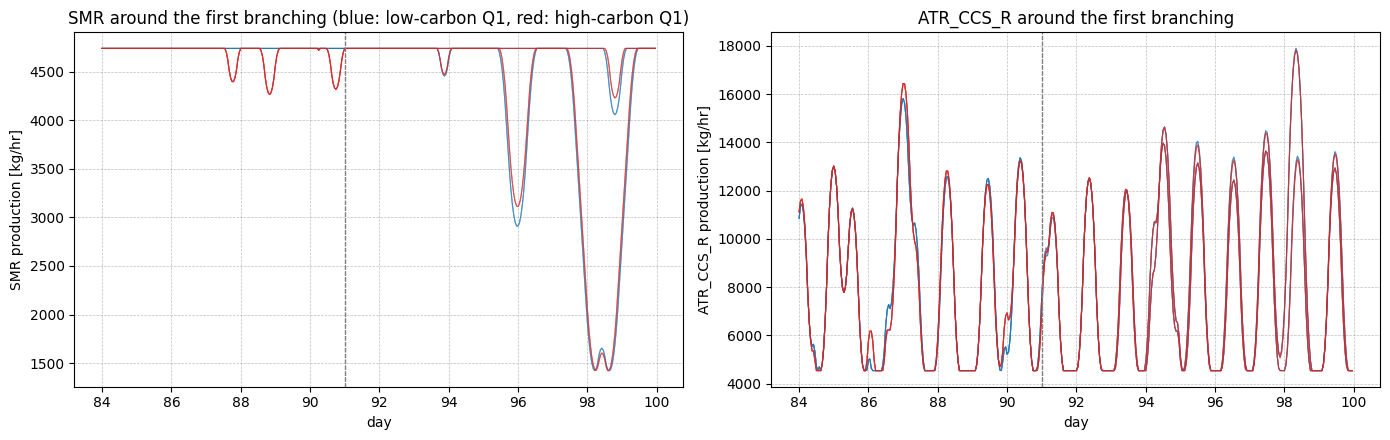

In [14]:
def plot_fan(model, process, day_from, day_to, ax, title):
    hours = range(day_from * 24, day_to * 24)
    for leaf in model.tree.leaves:
        P = model.scenario_frames(leaf)['P'].loc[process, list(hours)]
        first = model.tree.scenario_path(leaf)[0].label
        ax.plot(np.array(hours) / 24, P.to_numpy(), color='tab:blue' if first == 'low-carbon' else 'tab:red', alpha=0.35, linewidth=0.8)
    for n in model.tree.nodes:
        if not n.is_root and day_from * 24 < n.t0 < day_to * 24:
            ax.axvline(n.t0 / 24, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel('day')
    ax.set_ylabel(f'{process} production [kg/hr]')
    ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_fan(rp_each, 'SMR', 84, 100, axes[0], 'SMR around the first branching (blue: low-carbon Q1, red: high-carbon Q1)')
plot_fan(rp_each, 'ATR_CCS_R', 84, 100, axes[1], 'ATR_CCS_R around the first branching')
plt.tight_layout()
plt.show()

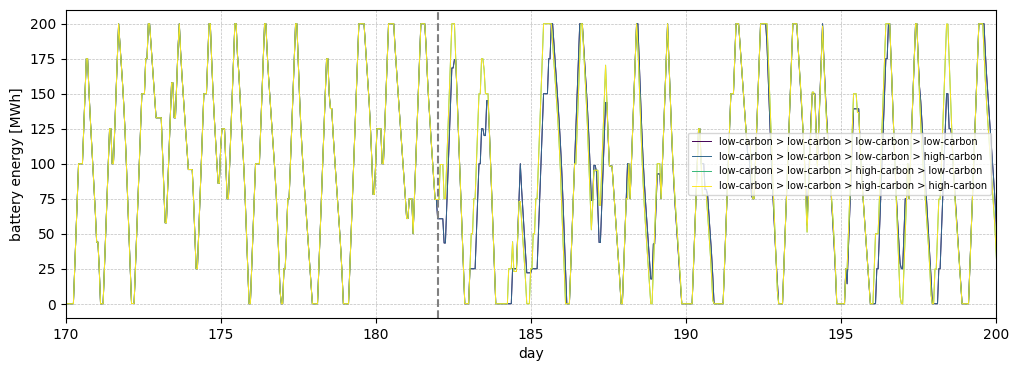

In [15]:
# battery state of charge of two scenarios that share the first two quarters and separate at day 182
leaves = rp_each.tree.leaves
same_prefix = [l for l in leaves if [n.label for n in rp_each.tree.scenario_path(l)[:2]] == ['low-carbon', 'low-carbon']]
fig, ax = plt.subplots(figsize=(12, 4))
for leaf, color in zip(same_prefix, plt.cm.viridis(np.linspace(0, 1, len(same_prefix)))):
    inv = rp_each.scenario_frames(leaf)['Inv'].iloc[0]
    ax.plot(inv.index / 24, inv.to_numpy(), color=color, linewidth=0.7,
            label=' > '.join(n.label for n in rp_each.tree.scenario_path(leaf)))
ax.axvline(182, color='gray', linestyle='--')
ax.set_xlim(170, 200)
ax.set_xlabel('day')
ax.set_ylabel('battery energy [MWh]')
ax.legend(fontsize=7)
ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
plt.show()

## 5. Notes for extending the tree

- **Here-and-now handles on the tree.** Epistemic quantities such as the realized capture rate are learned after
  commissioning but before operation. Put them in the *first-stage branches* (they are then constant along each path)
  and the design is chosen under their uncertainty while dispatch adapts to the realized value.
- **Finer stages.** `ScenarioTree.product([30] * 12, ...)` gives monthly stages; the node count grows as
  $b^{K}$ in the last stage, so keep $b^K$ below a few hundred node-slices, or use representative weeks.
- **Risk measures.** `add_gwp_cap(..., mode='each')` is the robust reading; a CVaR constraint on the scenario GWPs
  (`scenario_gwp(leaf)`) is a linear addition.
- **Rolling horizon.** The tree gives the design; the rolling-horizon layer evaluates it with forecasts inside each
  block instead of the block's exact realization.